# Lab 8: Classification using Decision Trees

### Objectives:
 1. Isolate the core financial features and binary target.
 2. Train Decision Tree classifiers with varying depth limits (`max_depth`).
 3. Compare Train vs. Test accuracy to observe algorithmic overfitting.
 4. Visualize the generated decision tree logic.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

In [6]:
df = pd.read_csv("/content/loan_approval_dataset.csv")
df.columns = df.columns.str.strip()

le = LabelEncoder()
df['loan_status'] = le.fit_transform(df['loan_status'])

X = df[['income_annum', 'loan_amount', 'loan_term', 'cibil_score']]
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7)

In [7]:
depths = [5, 10, None]
results = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, dt.predict(X_train))
    test_acc = accuracy_score(y_test, dt.predict(X_test))

    depth_label = str(d) if d is not None else 'None '
    results.append({'Max Depth': depth_label,
                    'Train Accuracy': train_acc,
                    'Test Accuracy': test_acc})

results_df = pd.DataFrame(results)
print("Experiment Results (Observing Overfitting):")
print(results_df.to_string(index=False))

Experiment Results (Observing Overfitting):
Max Depth  Train Accuracy  Test Accuracy
        5        0.971303       0.978923
       10        0.990044       0.982436
    None         1.000000       0.984778


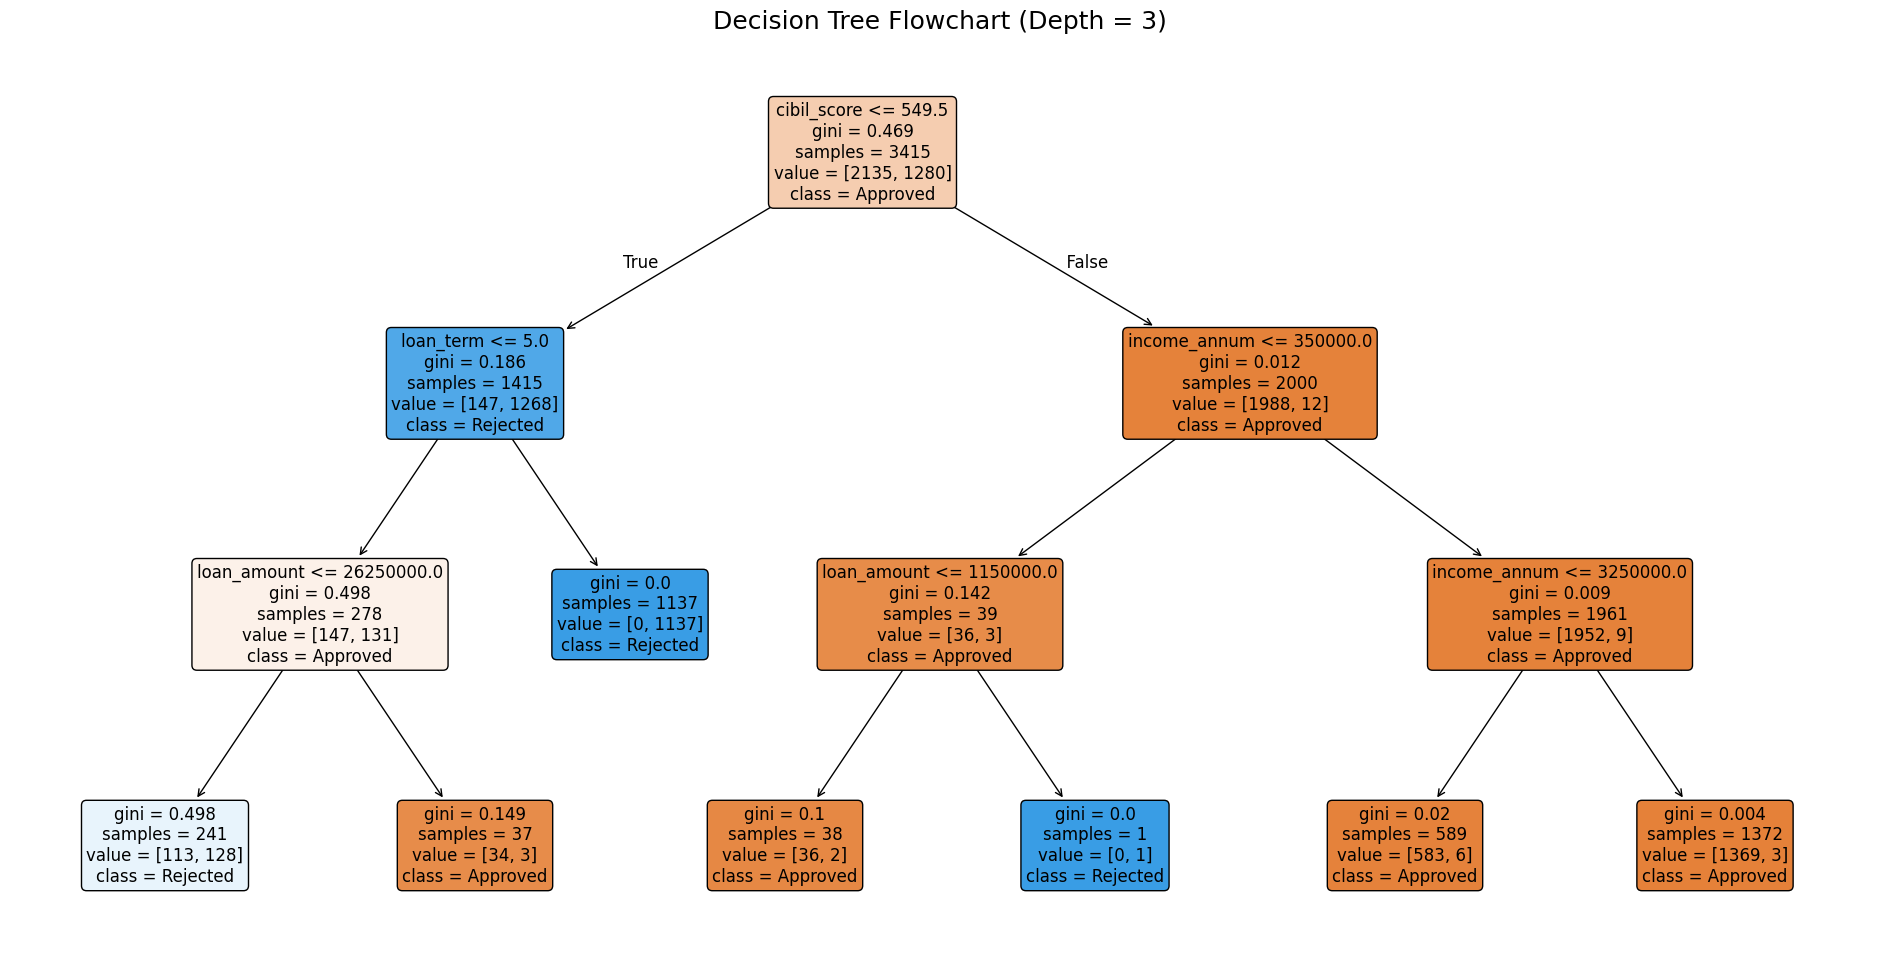

In [8]:
dt_visual = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_visual.fit(X_train, y_train)

plt.figure(figsize=(24, 12))
plot_tree(dt_visual,
          feature_names=X.columns,
          class_names=['Approved', 'Rejected'],
          filled=True,
          rounded=True,
          fontsize=12)
plt.title("Decision Tree Flowchart (Depth = 3)", fontsize=18)
plt.show()